<h1> Milestone 1 (2015) </h1>

In [2]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, root_mean_squared_error
import statsmodels.api as sm 

random_seed = 42

In [3]:
#Removing Frame
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True

<h3> Dataset Downloads </h3>

In [5]:
d15 = pd.read_csv('flights_2015.csv', low_memory = False)
d15.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              object 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          object 
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24

<h2> Dataset 1: 2015 Flight Delays and Causes </h2>

<h3> Data Dictionary </h3>

ALL TIMES ARE IN MILITARY TIME, ARRIVAL AND DEPARTURE TIMES ARE ADJUSTED WITH LOCAL TIMEZONES

- YEAR: Year of the flight trip
- MONTH: Month of the flight trip
- DAY: Day of the flight trip
- DAY_OF_WEEK: Day of week of the flight trip
- AIRLINE: Airline identifier
- FLIGHT_NUMBER: Flight identifier
- TAIL_NUMBER: Aircrage identifier
- ORIGIN_AIRPORT: Starting airport
- DESTINATION_AIRPORT: Destination airport
- SCHEDULED_DEPARTURE: Planned departure time
- DEPARTURE_TIME: WHEELS_OFF - TAXI_OUT
- DEPARTURE_DELAY: Total delay on departure (minutes)
- TAXI_OUT: Time duration elapsed between the origin airport gate and wheels off (minutes)
- WHEELS_OFF: The time point that the aircraft's wheels leave the ground
- SCHEDULED_TIME: Planned time amount for the flight trip
- ELAPSED_TIME: TAXI_OUT + AIR_TIME + TAXI_IN (minutes)
- AIR TIME: Time duration between WHEELS_OFF and WHEELS_ON times (minutes)
- DISTANCE: Distance between 2 airports (miles)
- WHEELS_ON: The time point that the aircraft's wheels touch on the ground
- TAXI_IN: The time duration elapsed between wheels-on and gate arrival at the destination airport (minutes)
- SCHEDULED_ARRIVAL: Arrival time
- ARRIVAL_TIME: WHEELS_ON + TAXI_IN
- ARRIVAL_DELAY: WHEELS_ON + TAXI_IN - SCHEDULED_ARRIVAL (minutes; if this value is positive, that means the flight got in early)
- DIVERTED: Aircraft landed on airport that out of schedule (0 or 1)
- CANCELLED: Flight Cancelled (1 = cancelled)
- CANCELLATION_REASON: Reason for Cancellation of flight: A - Airline/Carrier; B - Weather; C - National Air System; D - Security
- AIR_SYSTEM_DELAY: Delay caused by air system (minutes)
- SECURITY_DELAY: Delay caused by security (minutes)
- AIRLINE_DELAY: Delay caused by the airline (minutes)
- LATE_AIRCRAFT_DELAY: Delay caused by aircraft (minutes)
- WEATHER_DELAY: Delay caused by weather (minutes)

<h3> Preprocessing </h3>

In [10]:
all15 = d15.copy()

In [11]:
all15.head(5)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


<h3> Duplicate Rows, Missing Values </h3>

In [13]:
dupes_15 = all15[all15.duplicated()]
dupes_15

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY


<h3> Dummy-ing the null values in delay reason columns </h3>

In [15]:
all15[['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']] = all15[['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']].fillna(0)

<h3> Adding Full Names for Airlines (Important Later)</h3>

In [17]:
#mapping the airline abbreviations to full names

airline_map = {'UA': 'United Air Lines Inc.',
 'AA': 'American Airlines Inc.',
 'US': 'US Airways Inc.',
 'F9': 'Frontier Airlines Inc.',
 'B6': 'JetBlue Airways',
 'OO': 'Skywest Airlines Inc.',
 'AS': 'Alaska Airlines Inc.',
 'NK': 'Spirit Air Lines',
 'WN': 'Southwest Airlines Co.',
 'DL': 'Delta Air Lines Inc.',
 'EV': 'Atlantic Southeast Airlines',
 'HA': 'Hawaiian Airlines Inc.',
 'MQ': 'American Eagle Airlines Inc.',
 'VX': 'Virgin America'}

In [18]:
# Create new column 'Category' based on 'ID'
all15['AIRLINE_FULL'] = all15['AIRLINE'].map(airline_map)

In [19]:
all15.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,AIRLINE_FULL
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,-22.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,-9.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,5.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,US Airways Inc.
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,-9.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,-21.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.


<h3> What's going on w/ the canceled flights? </h3>

In [21]:
section = all15[all15['CANCELLATION_REASON'].notnull() & all15['CANCELLED'] == 1]
len(section)

89884

All cancelled flights will have a non-null cancellation reason.

In [23]:
len(all15) - len(section) #every flight with a null cancellation reason wasn't cancelled

5729195

In [24]:
all15['CANCELLATION_REASON'] = all15['CANCELLATION_REASON'].fillna('Not Canceled')

<h3> Null Tail Numbers </h3>

In [26]:
section = all15[all15['TAIL_NUMBER'].isnull()]
section.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14721 entries, 297 to 5818157
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 14721 non-null  int64  
 1   MONTH                14721 non-null  int64  
 2   DAY                  14721 non-null  int64  
 3   DAY_OF_WEEK          14721 non-null  int64  
 4   AIRLINE              14721 non-null  object 
 5   FLIGHT_NUMBER        14721 non-null  int64  
 6   TAIL_NUMBER          0 non-null      object 
 7   ORIGIN_AIRPORT       14721 non-null  object 
 8   DESTINATION_AIRPORT  14721 non-null  object 
 9   SCHEDULED_DEPARTURE  14721 non-null  int64  
 10  DEPARTURE_TIME       0 non-null      float64
 11  DEPARTURE_DELAY      0 non-null      float64
 12  TAXI_OUT             0 non-null      float64
 13  WHEELS_OFF           0 non-null      float64
 14  SCHEDULED_TIME       14721 non-null  float64
 15  ELAPSED_TIME         0 non-null      

Flights with no tail number appear to be cancelled flights.

In [28]:
all15['TAIL_NUMBER'] = all15['TAIL_NUMBER'].fillna('No Tail')

<h3> Null Values for Scheduled Time </h3>

In [30]:
section = all15[all15['SCHEDULED_TIME'].isnull()][['SCHEDULED_TIME', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON']]
section

,SCHEDULED_TIME,DIVERTED,CANCELLED,CANCELLATION_REASON
483174,NaN,0,1,B
619941,NaN,0,1,B
1720237,NaN,1,0,Not Canceled
1820960,NaN,0,1,B
2031482,NaN,0,1,B
2034453,NaN,0,1,C


Of the 6 flights with null scheduled time, 5 were canceled and 1 was diverted. I'm down to drop them.

In [32]:
all15 = all15.dropna(subset=['SCHEDULED_TIME'])

<h3>EQUAL Null Values for (Presumedly) Canceled Flights </h3>

In [34]:
# pulling the null values we're seeing for cancelled flights

cancel = all15[all15['CANCELLED'] == 1][['DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT',
                                         'WHEELS_OFF', 'ELAPSED_TIME', 'AIR_TIME',
                                         'WHEELS_ON', 'TAXI_IN', 'ARRIVAL_TIME',
                                         'ARRIVAL_DELAY']]
cancel.head()

,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,ELAPSED_TIME,AIR_TIME,WHEELS_ON,TAXI_IN,ARRIVAL_TIME,ARRIVAL_DELAY
32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
#finding values in this section that aren't null

section = cancel.notnull()
len(section)

89879

So here's what we have at this point:

- cancelled flights have no value departure time or departure delay, or most of the other variables pertaining to the flight

ngl I think we need to just separate the cancelled and non-cancelled flights

In [37]:
all15 = all15.dropna(subset=['SCHEDULED_TIME'])

<h3>Splitting up Cancelled and not cancelled flights</h3>

In [39]:
all15_nc = all15[all15.CANCELLED == 0]
all15_c = all15[all15.CANCELLED == 1]

In [40]:
print('Checking the columns for null values:')
print()

for col in all15_nc:
        rows_with_null = all15_nc[all15_nc[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 0
DEPARTURE_DELAY 0
TAXI_OUT 0
WHEELS_OFF 0
SCHEDULED_TIME 0
ELAPSED_TIME 15186
AIR_TIME 15186
DISTANCE 0
WHEELS_ON 2628
TAXI_IN 2628
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 2628
ARRIVAL_DELAY 15186
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
AIRLINE_FULL 0


In [41]:
print('Checking the columns for null values:')
print()

for col in all15_c:
        rows_with_null = all15_c[all15_c[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 0
ELAPSED_TIME 89879
AIR_TIME 89879
DISTANCE 0
WHEELS_ON 89879
TAXI_IN 89879
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 89879
ARRIVAL_DELAY 89879
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
AIRLINE_FULL 0


In [42]:
# dropping nulls from non-cancelled flights (15186 out of over 5 million rows, negligible)

all15_nc = all15_nc.dropna()

print('Checking the columns for null values:')
print()

for col in all15_nc:
        rows_with_null = all15_nc[all15_nc[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 0
DEPARTURE_DELAY 0
TAXI_OUT 0
WHEELS_OFF 0
SCHEDULED_TIME 0
ELAPSED_TIME 0
AIR_TIME 0
DISTANCE 0
WHEELS_ON 0
TAXI_IN 0
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 0
ARRIVAL_DELAY 0
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
AIRLINE_FULL 0


In [43]:
#keeping just the cancellation info for the canceled flights

all15_c = all15_c.drop(['DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'ELAPSED_TIME',
                       'AIR_TIME', 'WHEELS_ON', 'TAXI_IN', 'ARRIVAL_TIME', 'ARRIVAL_DELAY',
                       'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY'], axis = 1)

for col in all15_c:
        rows_with_null = all15_c[all15_c[col].isnull()]
        print(col, len(rows_with_null))

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
SCHEDULED_TIME 0
DISTANCE 0
SCHEDULED_ARRIVAL 0
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIRLINE_FULL 0


First preprocessing steps:

- Dummied down the variables for different types of delays
- Labeled flights with no tail numbers
- Dropped rows with no SCHEDULED_TIME (projected trip time)
- Created a TOTAL_DELAY column (elapsed_time - scheduled time)
- Split up cancelled and non-cancelled flights (instead of merging them with another one)
- Non-cancelled: dropped nulls, 15186 rows
- Cancelled: dropped irrelevant columns (cancelled flights aren't delayed fam)

<h3> Encoding Categorical Variables</h3>

In [46]:
#for non-cancelled first

cat_15nc = all15_nc.select_dtypes(include=['object'])
cat_15nc

,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON,AIRLINE_FULL
0,AS,N407AS,ANC,SEA,Not Canceled,Alaska Airlines Inc.
1,AA,N3KUAA,LAX,PBI,Not Canceled,American Airlines Inc.
2,US,N171US,SFO,CLT,Not Canceled,US Airways Inc.
3,AA,N3HYAA,LAX,MIA,Not Canceled,American Airlines Inc.
4,AS,N527AS,SEA,ANC,Not Canceled,Alaska Airlines Inc.
...,...,...,...,...,...,...
5819074,B6,N657JB,LAX,BOS,Not Canceled,JetBlue Airways
5819075,B6,N828JB,JFK,PSE,Not Canceled,JetBlue Airways
5819076,B6,N913JB,JFK,SJU,Not Canceled,JetBlue Airways
5819077,B6,N527JB,MCO,SJU,Not Canceled,JetBlue Airways


In [47]:
cat_15c = all15_c.select_dtypes(include=['object'])
cat_15c

,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON,AIRLINE_FULL
32,AS,N431AS,ANC,SEA,A,Alaska Airlines Inc.
42,AA,N3BDAA,PHX,DFW,B,American Airlines Inc.
68,OO,N746SK,MAF,IAH,B,Skywest Airlines Inc.
82,MQ,N660MQ,SGF,DFW,B,American Eagle Airlines Inc.
90,OO,N583SW,RDD,SFO,A,Skywest Airlines Inc.
...,...,...,...,...,...,...
5818090,UA,No Tail,IAH,TPA,A,United Air Lines Inc.
5818157,UA,No Tail,SFO,LAX,A,United Air Lines Inc.
5818318,AA,N880AA,MIA,SAN,A,American Airlines Inc.
5818777,NK,N522NK,FLL,IAG,A,Spirit Air Lines


In [48]:
len(pd.unique(cat_15c.TAIL_NUMBER))

3846

In [49]:
#encoding the cancellation reasons for cancelled flights

cancels = pd.get_dummies(all15_c['CANCELLATION_REASON'], prefix = 'CANCELLATION', dtype = int)
all15_c = all15_c.join(cancels)
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,DISTANCE,SCHEDULED_ARRIVAL,DIVERTED,CANCELLED,CANCELLATION_REASON,AIRLINE_FULL,CANCELLATION_A,CANCELLATION_B,CANCELLATION_C,CANCELLATION_D
32,2015,1,1,4,AS,136,N431AS,ANC,SEA,135,...,1448,600,0,1,A,Alaska Airlines Inc.,1,0,0,0
42,2015,1,1,4,AA,2459,N3BDAA,PHX,DFW,200,...,868,500,0,1,B,American Airlines Inc.,0,1,0,0
68,2015,1,1,4,OO,5254,N746SK,MAF,IAH,510,...,429,637,0,1,B,Skywest Airlines Inc.,0,1,0,0
82,2015,1,1,4,MQ,2859,N660MQ,SGF,DFW,525,...,364,700,0,1,B,American Eagle Airlines Inc.,0,1,0,0
90,2015,1,1,4,OO,5460,N583SW,RDD,SFO,530,...,199,700,0,1,A,Skywest Airlines Inc.,1,0,0,0


In [50]:
#renaming them

all15_c['CANCELLATION_AIRLINE'] = all15_c['CANCELLATION_A']
all15_c['CANCELLATION_WEATHER'] = all15_c['CANCELLATION_B']
all15_c['CANCELLATION_SYSTEM'] = all15_c['CANCELLATION_C']
all15_c['CANCELLATION_SECURITY'] = all15_c['CANCELLATION_D']

all15_c = all15_c.drop(['CANCELLATION_A', 'CANCELLATION_B', 'CANCELLATION_C', 'CANCELLATION_D'], axis = 1)
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,DISTANCE,SCHEDULED_ARRIVAL,DIVERTED,CANCELLED,CANCELLATION_REASON,AIRLINE_FULL,CANCELLATION_AIRLINE,CANCELLATION_WEATHER,CANCELLATION_SYSTEM,CANCELLATION_SECURITY
32,2015,1,1,4,AS,136,N431AS,ANC,SEA,135,...,1448,600,0,1,A,Alaska Airlines Inc.,1,0,0,0
42,2015,1,1,4,AA,2459,N3BDAA,PHX,DFW,200,...,868,500,0,1,B,American Airlines Inc.,0,1,0,0
68,2015,1,1,4,OO,5254,N746SK,MAF,IAH,510,...,429,637,0,1,B,Skywest Airlines Inc.,0,1,0,0
82,2015,1,1,4,MQ,2859,N660MQ,SGF,DFW,525,...,364,700,0,1,B,American Eagle Airlines Inc.,0,1,0,0
90,2015,1,1,4,OO,5460,N583SW,RDD,SFO,530,...,199,700,0,1,A,Skywest Airlines Inc.,1,0,0,0


In [51]:
all15_nc = all15_nc.drop(['CANCELLED', 'CANCELLATION_REASON'], axis = 1)
all15_nc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5714008 entries, 0 to 5819078
Data columns (total 30 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              object 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          object 
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24  AIR

In [52]:
all15_c.info()

<class 'pandas.core.frame.DataFrame'>
Index: 89879 entries, 32 to 5818843
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   YEAR                   89879 non-null  int64  
 1   MONTH                  89879 non-null  int64  
 2   DAY                    89879 non-null  int64  
 3   DAY_OF_WEEK            89879 non-null  int64  
 4   AIRLINE                89879 non-null  object 
 5   FLIGHT_NUMBER          89879 non-null  int64  
 6   TAIL_NUMBER            89879 non-null  object 
 7   ORIGIN_AIRPORT         89879 non-null  object 
 8   DESTINATION_AIRPORT    89879 non-null  object 
 9   SCHEDULED_DEPARTURE    89879 non-null  int64  
 10  SCHEDULED_TIME         89879 non-null  float64
 11  DISTANCE               89879 non-null  int64  
 12  SCHEDULED_ARRIVAL      89879 non-null  int64  
 13  DIVERTED               89879 non-null  int64  
 14  CANCELLED              89879 non-null  int64  
 15  CANC

Second set of preprocessing steps:

- Encoded the 4 cancellation reasons

We kept the original variables because we can use those for barplots later

<h3>Creating DATE Column</h3>

In [55]:
#creating binary variable from what we have 

all15_nc['IS_SW'] = [1 if i == 'WN' else 0 for i in all15_nc.AIRLINE]

In [56]:
all15_nc['DATE'] = pd.to_datetime(all15_nc[['YEAR', 'MONTH', 'DAY']])
all15_c['DATE'] = pd.to_datetime(all15_c[['YEAR', 'MONTH', 'DAY']])

In [57]:
all15_nc.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_DELAY,DIVERTED,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,AIRLINE_FULL,IS_SW,DATE
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,-22.0,0,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.,0,2015-01-01
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,-9.0,0,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.,0,2015-01-01
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,5.0,0,0.0,0.0,0.0,0.0,0.0,US Airways Inc.,0,2015-01-01
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,-9.0,0,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.,0,2015-01-01
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,-21.0,0,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.,0,2015-01-01


Last set of preprocessing (2015):

- Changed CANCELLATION_REASON from coded letter to the actual reason (below)
- Created datetime column from YEAR, MONTH, and DAY

Non-Cancelled Flights: 5714008 flights
Cancelled Flights: 89879 flights

<h3>EDA - Multivariate Analysis</h3>

Keeping the correlation matrix for reference

In [61]:
number15= all15_nc.drop(['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'FLIGHT_NUMBER', 'AIRLINE', 'AIRLINE_FULL',
                         'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE',
                        'DEPARTURE_TIME', 'WHEELS_OFF', 'WHEELS_ON', 'SCHEDULED_ARRIVAL',
                        'ARRIVAL_TIME', 'DATE', 'DIVERTED'], axis =1) #creating df of numeric columns only to run correlation matrix

corrs = number15.corr()

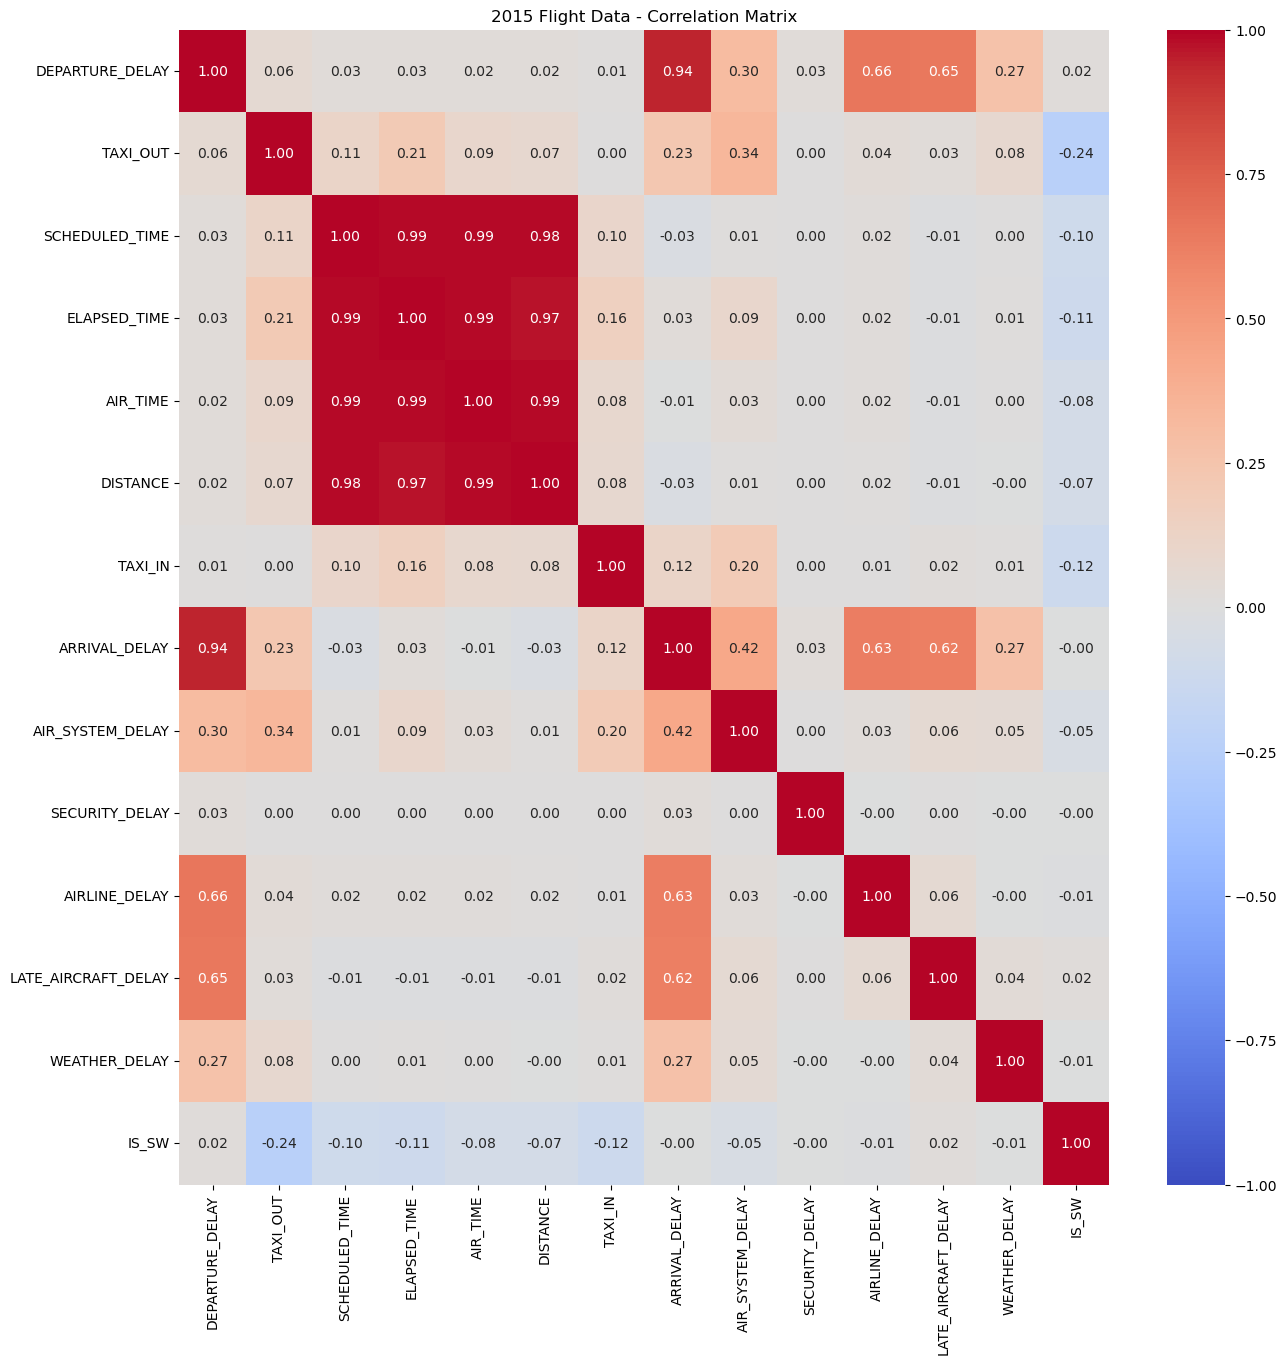

In [62]:
plt.figure(figsize=(15, 15))

# Making a heatmap
sns.heatmap(corrs,
            annot=True,     # Annotate each cell with the correlation value
            fmt=".2f",      # Set the annotation format to two decimal places
            cmap='coolwarm',# Choose a divergent color map
            vmin=-1, vmax=1,# Ensure the color scale ranges from -1 to 1
            center=0        # Center the color map at 0
           )

# Display the plot
plt.title('2015 Flight Data - Correlation Matrix')
plt.show()

What we know:

- Arrival and Departure delay seem to be almost perfectly correlated (makes sense)
- Our created target variable TOTAL_DELAY: 2 highest positive correlations are with TAXI_OUT (0.53) and AIR_SYSTEM_DELAY (0.42)
- The original target variables: ARRIVAL_DELAY highly correlated with AIRLINE_DELAY (0.63) and LATE_AIRCRAFT_DELAY (0.62), DEPARTURE_DELAY highly correlated with AIRLINE_DELAY (0.66) and LATE_AIRCRAFT_DELAY (0.65)
- Distance not highly correlated with anything
- None of the encoded airline variables are super strongly correlated with our targets

<h3>Linear Regression w/ Polynomial & Interaction Terms</h3>

In [112]:
#standard scaling the numerical data

sc = StandardScaler()

sc15 = sc.fit_transform(number15)
df_scaled = pd.DataFrame(sc15, columns=number15.columns)
df_scaled.head()

,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,TAXI_IN,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,IS_SW,SQUARE_DIST
0,-0.550149,0.555534,0.837906,0.767996,0.768209,1.024449,-0.610268,-0.672426,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,0.643869
1,-0.468826,-0.457700,1.833737,1.913378,2.069593,2.473529,-0.610268,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.694024
2,-0.306179,-0.007374,1.913403,2.102029,2.111126,2.417669,0.635517,0.015099,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.597254
3,-0.387502,-0.119955,1.900125,1.940328,2.000370,2.493245,0.101609,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.728518
4,-0.279071,-0.570282,1.236238,1.050973,1.183544,1.024449,-0.432298,-0.646963,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,0.643869


In [114]:
#predicting the departure delay time from the different special delay types (baseline model)

delay_types = ['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']

print('Baseline Model:')
print()

lr1 = LinearRegression()

lr1.fit(df_scaled[delay_types], df_scaled.DEPARTURE_DELAY)

coeff_df1 = pd.Series(lr1.coef_, index=df_scaled[delay_types].columns)
print(coeff_df1)
print()

y_pred1 = lr1.predict(df_scaled[delay_types])
print('RMSE (DEPARTURE_DELAY):', root_mean_squared_error(y_pred1, df_scaled.DEPARTURE_DELAY))

Baseline Model:

AIR_SYSTEM_DELAY       0.241949
SECURITY_DELAY         0.026443
AIRLINE_DELAY          0.618079
LATE_AIRCRAFT_DELAY    0.594337
WEATHER_DELAY          0.234371
dtype: float64

RMSE (DEPARTURE_DELAY): 0.26229558917903384


In [116]:
#let's add term for squared distance and run the regression again

number15['SQUARE_DIST'] = number15.DISTANCE **2

In [118]:
sc15 = sc.fit_transform(number15)
df_scaled = pd.DataFrame(sc15, columns=number15.columns)
df_scaled.head()

,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,TAXI_IN,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,IS_SW,SQUARE_DIST
0,-0.550149,0.555534,0.837906,0.767996,0.768209,1.024449,-0.610268,-0.672426,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,0.643869
1,-0.468826,-0.457700,1.833737,1.913378,2.069593,2.473529,-0.610268,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.694024
2,-0.306179,-0.007374,1.913403,2.102029,2.111126,2.417669,0.635517,0.015099,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.597254
3,-0.387502,-0.119955,1.900125,1.940328,2.000370,2.493245,0.101609,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.728518
4,-0.279071,-0.570282,1.236238,1.050973,1.183544,1.024449,-0.432298,-0.646963,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,0.643869


In [120]:
inputs = ['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY', 'SQUARE_DIST']

In [122]:
X = sm.add_constant(df_scaled[inputs]) 
y = df_scaled.DEPARTURE_DELAY
model = sm.OLS(y, X) 
results = model.fit() 
print(results.summary()) 

                            OLS Regression Results                            
Dep. Variable:        DEPARTURE_DELAY   R-squared:                       0.931
Model:                            OLS   Adj. R-squared:                  0.931
Method:                 Least Squares   F-statistic:                 1.294e+07
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        19:33:46   Log-Likelihood:            -4.4968e+05
No. Observations:             5714008   AIC:                         8.994e+05
Df Residuals:                 5714001   BIC:                         8.995e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                3.442e-14    

In [124]:
#taking the product of AIRLINE_DELAY and SECURITY_DELAY as an input

number15['DELAY_PROD'] = number15.AIRLINE_DELAY * number15.SECURITY_DELAY

In [126]:
sc15 = sc.fit_transform(number15)
df_scaled = pd.DataFrame(sc15, columns=number15.columns)
df_scaled.head()

,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,TAXI_IN,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,IS_SW,SQUARE_DIST,DELAY_PROD
0,-0.550149,0.555534,0.837906,0.767996,0.768209,1.024449,-0.610268,-0.672426,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,0.643869,-0.002471
1,-0.468826,-0.457700,1.833737,1.913378,2.069593,2.473529,-0.610268,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.694024,-0.002471
2,-0.306179,-0.007374,1.913403,2.102029,2.111126,2.417669,0.635517,0.015099,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.597254,-0.002471
3,-0.387502,-0.119955,1.900125,1.940328,2.000370,2.493245,0.101609,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.728518,-0.002471
4,-0.279071,-0.570282,1.236238,1.050973,1.183544,1.024449,-0.432298,-0.646963,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,0.643869,-0.002471


In [128]:
inputs = ['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY', 'DELAY_PROD']

In [130]:
X = sm.add_constant(df_scaled[inputs]) 
y = df_scaled.DEPARTURE_DELAY
model = sm.OLS(y, X) 
results = model.fit() 
print(results.summary()) 

                            OLS Regression Results                            
Dep. Variable:        DEPARTURE_DELAY   R-squared:                       0.931
Model:                            OLS   Adj. R-squared:                  0.931
Method:                 Least Squares   F-statistic:                 1.289e+07
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        19:33:55   Log-Likelihood:            -4.6087e+05
No. Observations:             5714008   AIC:                         9.217e+05
Df Residuals:                 5714001   BIC:                         9.218e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                3.436e-14    

<h3>Lasso Regression</H3>

In [133]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

In [135]:
inputs = list(df_scaled.drop(['DEPARTURE_DELAY'], axis = 1).columns)
inputs #setting our list of inputs to all variables to see what the Lasso keeps

['TAXI_OUT',
 'SCHEDULED_TIME',
 'ELAPSED_TIME',
 'AIR_TIME',
 'DISTANCE',
 'TAXI_IN',
 'ARRIVAL_DELAY',
 'AIR_SYSTEM_DELAY',
 'SECURITY_DELAY',
 'AIRLINE_DELAY',
 'LATE_AIRCRAFT_DELAY',
 'WEATHER_DELAY',
 'IS_SW',
 'SQUARE_DIST',
 'DELAY_PROD']

In [137]:
#Initialize and fit Lasso
# 'alpha' controls penalty strength (default=1.0)

lasso = Lasso(alpha=0.1)
lasso.fit(df_scaled[inputs], df_scaled.DEPARTURE_DELAY)

Lasso(alpha=0.1)

In [139]:
#Results Station
lasso_pred = lasso.predict(df_scaled[inputs])
print("Intercept:", lasso.intercept_)
print("Coefficients:", lasso.coef_)  # Unimportant features will be 0.0
print("RMSE:", root_mean_squared_error(lasso_pred, df_scaled.DEPARTURE_DELAY))

Intercept: -3.178212811140468e-17
Coefficients: [-0.01398733  0.          0.          0.          0.         -0.
  0.73208096 -0.          0.          0.0942424   0.0909777   0.
  0.          0.          0.        ]
RMSE: 0.30785317399277307


<h3>Ridge Regression</h3>

In [142]:
#Initialize and fit Ridge
# 'alpha' controls penalty strength (default=1.0)

ridge = Ridge(alpha=0.1)
ridge.fit(df_scaled[inputs], df_scaled.DEPARTURE_DELAY)

Ridge(alpha=0.1)

In [144]:
#Results Station
ridge_pred = ridge.predict(df_scaled[inputs])
print("Intercept:", ridge.intercept_)
print("Coefficients:", ridge.coef_)  # all features will be used
print("RMSE:", root_mean_squared_error(ridge_pred, df_scaled.DEPARTURE_DELAY))

Intercept: 1.5598997666829917e-16
Coefficients: [-1.22386611e-01  2.04159269e+00 -9.89182148e-01 -9.95228261e-01
  5.19770656e-07 -7.74205941e-02  1.06455738e+00  4.47422579e-07
  4.62733250e-08  1.09914322e-06  1.05896023e-06  4.23505292e-07
 -3.36279894e-08 -9.29834398e-08 -2.09860441e-10]
RMSE: 2.2687852325070373e-05


<h3>Elastic Net Regression</h3>

In [147]:
#Initialize the ElasticNet model
#alpha defines overall penalty; l1_ratio defines the L1 vs L2 mix (e.g., 70% Lasso, 30% Ridge)
net = ElasticNet(alpha=0.5, l1_ratio=0.7, random_state= random_seed)
net.fit(df_scaled[inputs], df_scaled.DEPARTURE_DELAY)

ElasticNet(alpha=0.5, l1_ratio=0.7, random_state=42)

In [149]:
#View the model coefficients
net_pred = net.predict(df_scaled[inputs])
print("Intercept:", net.intercept_)
print("Model Coefficients:", net.coef_)
print("RMSE:", root_mean_squared_error(net_pred, df_scaled.DEPARTURE_DELAY))

Intercept: -3.270851435366799e-17
Model Coefficients: [-0.          0.          0.          0.          0.         -0.
  0.51710566  0.          0.          0.          0.          0.
  0.          0.          0.        ]
RMSE: 0.5388954340537886


<h3>Forward and Backward Selection</h3>

In [152]:
inputs = list(df_scaled.drop(['DEPARTURE_DELAY', 'ARRIVAL_DELAY'], axis = 1).columns)
inputs

['TAXI_OUT',
 'SCHEDULED_TIME',
 'ELAPSED_TIME',
 'AIR_TIME',
 'DISTANCE',
 'TAXI_IN',
 'AIR_SYSTEM_DELAY',
 'SECURITY_DELAY',
 'AIRLINE_DELAY',
 'LATE_AIRCRAFT_DELAY',
 'WEATHER_DELAY',
 'IS_SW',
 'SQUARE_DIST',
 'DELAY_PROD']

In [154]:
#running the forward selection with the input features, all numerical variables, linear regression base
from sklearn.feature_selection import SequentialFeatureSelector

lrf = LinearRegression()

sfs = SequentialFeatureSelector(lrf, n_features_to_select = 5, direction='forward', cv = 5)
sfs.fit(df_scaled[inputs], df_scaled.DEPARTURE_DELAY)

SequentialFeatureSelector(estimator=LinearRegression(), n_features_to_select=5)

In [156]:
#grabbing the features the selection picked

fwd_vars = list(sfs.get_feature_names_out())
fwd_vars

['TAXI_OUT',
 'AIR_SYSTEM_DELAY',
 'AIRLINE_DELAY',
 'LATE_AIRCRAFT_DELAY',
 'WEATHER_DELAY']

In [158]:
#fitting the forward selected variables

lrf.fit(df_scaled[fwd_vars], df_scaled.DEPARTURE_DELAY)
print('Regression w/ Forward Selection:')
print()

coeff_fwd = pd.Series(lrf.coef_, index=df_scaled[fwd_vars].columns)
print(coeff_fwd)
print()

y_pred1 = lrf.predict(df_scaled[fwd_vars])
print('RMSE (DEPARTURE_DELAY):', root_mean_squared_error(y_pred1, df_scaled.DEPARTURE_DELAY))

Regression w/ Forward Selection:

TAXI_OUT              -0.091543
AIR_SYSTEM_DELAY       0.272603
AIRLINE_DELAY          0.620462
LATE_AIRCRAFT_DELAY    0.594964
WEATHER_DELAY          0.239862
dtype: float64

RMSE (DEPARTURE_DELAY): 0.24922520313858226


In [160]:
#running the backward selection with the input features, all numerical variables, linear regression base

lrb = LinearRegression()

sfs = SequentialFeatureSelector(lrb, n_features_to_select = 5, direction='backward', cv = 5)
sfs.fit(df_scaled[inputs], df_scaled.DEPARTURE_DELAY)

SequentialFeatureSelector(direction='backward', estimator=LinearRegression(),
                          n_features_to_select=5)

In [162]:
#grabbing the features the selection picked

bck_vars = list(sfs.get_feature_names_out())
bck_vars

['SCHEDULED_TIME',
 'AIR_SYSTEM_DELAY',
 'AIRLINE_DELAY',
 'LATE_AIRCRAFT_DELAY',
 'WEATHER_DELAY']

In [164]:
#fitting the backward selected variables

lrb.fit(df_scaled[bck_vars], df_scaled.DEPARTURE_DELAY)
print('Regression w/ Backward Selection:')
print()

coeff_bck = pd.Series(lrb.coef_, index=df_scaled[bck_vars].columns)
print(coeff_bck)
print()

y_pred1 = lrb.predict(df_scaled[bck_vars])
print('RMSE (DEPARTURE_DELAY):', root_mean_squared_error(y_pred1, df_scaled.DEPARTURE_DELAY))

Regression w/ Backward Selection:

SCHEDULED_TIME         0.022761
AIR_SYSTEM_DELAY       0.241678
AIRLINE_DELAY          0.617666
LATE_AIRCRAFT_DELAY    0.594799
WEATHER_DELAY          0.234343
dtype: float64

RMSE (DEPARTURE_DELAY): 0.2626414201048357


<h3>Principal Component Regression</h3>

In [167]:
#Running PCA to reduce the input space into 5 components

from sklearn.decomposition import PCA

pca = PCA(n_components = 5).set_output(transform="pandas")

df_pca = pca.fit_transform(df_scaled[inputs])
df_pca.head()

,pca0,pca1,pca2,pca3,pca4
0,1.827687,-0.008542,-0.033037,-0.384305,-0.745099
1,4.829007,-0.950577,-0.021670,-0.214753,-0.445527
2,5.005160,-0.291385,-0.051282,-0.374632,0.289659
3,4.928318,-0.535442,-0.039095,-0.312209,-0.056028
4,2.251253,-0.650874,-0.027718,-0.307844,-0.222413


In [169]:
#running a linear regression with the PCA vars

ps = list(df_pca.columns)
print('PCR Results:')
print()

lrp = LinearRegression()

lrp.fit(df_pca[ps], df_scaled.DEPARTURE_DELAY)

coeff_df1 = pd.Series(lrp.coef_, index=df_pca[ps].columns)
print(coeff_df1)
print()

y_pred1 = lrp.predict(df_pca[ps])
print('RMSE (DEPARTURE_DELAY):', root_mean_squared_error(y_pred1, df_scaled.DEPARTURE_DELAY))

PCR Results:

pca0    0.014349
pca1    0.262363
pca2    0.091893
pca3    0.831375
pca4    0.055857
dtype: float64

RMSE (DEPARTURE_DELAY): 0.38172516976945725


<h3>Partial Least Squares Regression</h3>

In [172]:
#running partial least squares w/ 5 components
from sklearn.cross_decomposition import PLSRegression

pls = PLSRegression(n_components=5)
pls.fit(df_scaled[inputs], df_scaled.DEPARTURE_DELAY)

print('Partial Least Squares Regression:')
print()

y_pred1 = pls.predict(df_scaled[inputs])
print('RMSE (DEPARTURE_DELAY):', root_mean_squared_error(y_pred1, df_scaled.DEPARTURE_DELAY))

Partial Least Squares Regression:

RMSE (DEPARTURE_DELAY): 0.23456655532078766


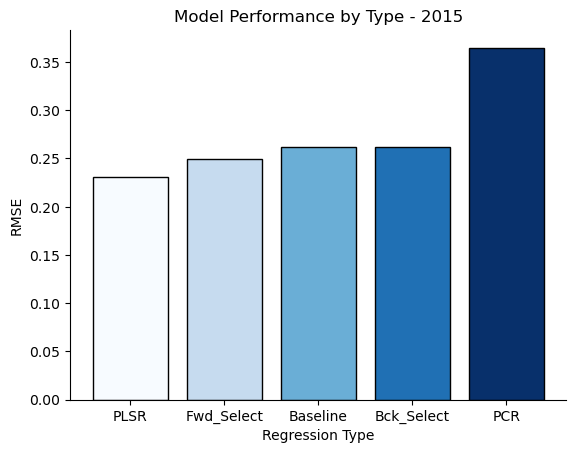

In [174]:
#graping station

regs = ['Baseline', 'Fwd_Select', 'Bck_Select', 'PCR', 'PLSR']

rmses = [0.262, 0.249, 0.262, 0.365, 0.231]

data = {'Regressions': regs, 'RMSE': rmses}

df = pd.DataFrame(data)

# Sort DataFrame by the 'Values' column (Use ascending=False for descending order)
df_sorted = df.sort_values('RMSE', ascending=True)

cmap = plt.get_cmap('Blues')
colors = cmap(np.linspace(0, 1, len(regs)))

# Plot the sorted data
plt.bar(df_sorted['Regressions'], df_sorted['RMSE'], color = colors, edgecolor = 'black')
plt.xlabel('Regression Type')
plt.ylabel('RMSE')
plt.title('Model Performance by Type - 2015')
plt.show()

<h3>Logistic Regression</h3>

In [177]:
from sklearn.linear_model import LogisticRegression

log_r = LogisticRegression()

log_r.fit(df_scaled[fwd_vars], number15.IS_SW)

LogisticRegression()

In [179]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score, classification_report, confusion_matrix

y_pred = log_r.predict(df_scaled[fwd_vars])

#full classification metrics report
print('\t\t\t\tCLASSIFICATIION METRICS\n')
print(classification_report(number15.IS_SW, y_pred))
print()

print('Model Accuracy:', round(log_r.score(df_scaled[fwd_vars], number15.IS_SW), 3))

				CLASSIFICATIION METRICS

              precision    recall  f1-score   support

           0       0.78      1.00      0.88   4471605
           1       0.48      0.02      0.03   1242403

    accuracy                           0.78   5714008
   macro avg       0.63      0.51      0.45   5714008
weighted avg       0.72      0.78      0.69   5714008


Model Accuracy: 0.782


<h3>SVMS + Regularization </h3>

In [240]:
#making a sample of the scaled dataset to run the cross validation for the SVMs(whole thing is too large and will likely crash the server)
sampled_df = df_scaled.sample(frac=0.1)

In [244]:
sampled_df.head()

,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,TAXI_IN,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,IS_SW,SQUARE_DIST,DELAY_PROD
5215658,-0.251963,-0.345119,-0.967868,-1.051140,-1.003888,-0.983234,-0.432298,-0.366860,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,-0.614717,-0.002471
1091830,-0.306179,-0.570282,-0.290703,-0.363911,-0.353196,-0.399987,0.635517,-0.417788,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,-0.438455,-0.002471
1710018,-0.360394,0.893279,0.492684,1.064448,0.948188,0.367270,0.457547,0.728088,2.315016,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,0.029597,-0.002471
1509592,-0.441718,-0.457700,0.466129,0.350269,0.422096,0.263764,-0.076360,-0.646963,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,-0.049204,-0.002471
4988030,-0.414610,-0.457700,1.475238,1.549551,1.681947,2.082508,-0.432298,-0.290468,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108,2.046506,-0.002471


In [246]:
#using an SVM Regressor to run regression on the inputs (no regularization yet)
from sklearn import svm
svr = svm.LinearSVR(C = 0.1 , max_iter=1500, random_state = random_seed)

svr.fit(sampled_df[fwd_vars], sampled_df.DEPARTURE_DELAY)

LinearSVR(C=0.1, max_iter=1500, random_state=42)

In [248]:
#pulling coefficients and making predictions
print('Regression w/ SVMs:')
print()

coeff_svm = pd.Series(svr.coef_, index=sampled_df[fwd_vars].columns)
print(coeff_svm)
print()

y_pred1 = svr.predict(sampled_df[fwd_vars])
print('RMSE (DepDelay):', root_mean_squared_error(y_pred1, sampled_df.DEPARTURE_DELAY))

Regression w/ SVMs:

TAXI_OUT              -0.021926
AIR_SYSTEM_DELAY       0.073867
AIRLINE_DELAY          0.636077
LATE_AIRCRAFT_DELAY    0.609081
WEATHER_DELAY          0.246692
dtype: float64

RMSE (DepDelay): 0.31501807744031646


<h3>Working with Regularization Terms</h3>

In [251]:
#1. LinearSVR is sensitive to feature scales, so scaling is strongly recommended

# 2. Define the hyperparameter grid to search
param_grid = {
    'C': [0.1, 0.5, 1.0, 1.5]
}

svr_G = svm.LinearSVR(random_state = random_seed)

# 3. Setup GridSearchCV
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=svr_G,
    param_grid=param_grid,
    cv=5,                 # 5-fold cross-validation
    scoring='neg_root_mean_squared_error',
    n_jobs=-1             # Use all available CPU cores for faster processing
)

# 4. Fit the grid search to your training data
grid_search.fit(sampled_df[fwd_vars], sampled_df.DEPARTURE_DELAY)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the n

GridSearchCV(cv=5, estimator=LinearSVR(random_state=42), n_jobs=-1,
             param_grid={'C': [0.1, 0.5, 1.0, 1.5]},
             scoring='neg_root_mean_squared_error')

In [253]:
#View the best parameters and the best score
print("Best Parameters:", grid_search.best_params_)
print("Best Accuracy:", grid_search.best_score_)

Best Parameters: {'C': 0.5}
Best Accuracy: -0.3147113033948103


In [255]:
#viewing all the grid search results

results_df = pd.DataFrame(grid_search.cv_results_)[['param_C', 'mean_test_score', 'std_test_score','rank_test_score']]
results_df['RMSE'] = -results_df['mean_test_score']
results_df

,param_C,mean_test_score,std_test_score,rank_test_score,RMSE
0,0.1,-0.314727,0.007182,2,0.314727
1,0.5,-0.314711,0.007086,1,0.314711
2,1.0,-0.315564,0.007595,3,0.315564
3,1.5,-0.317178,0.008844,4,0.317178


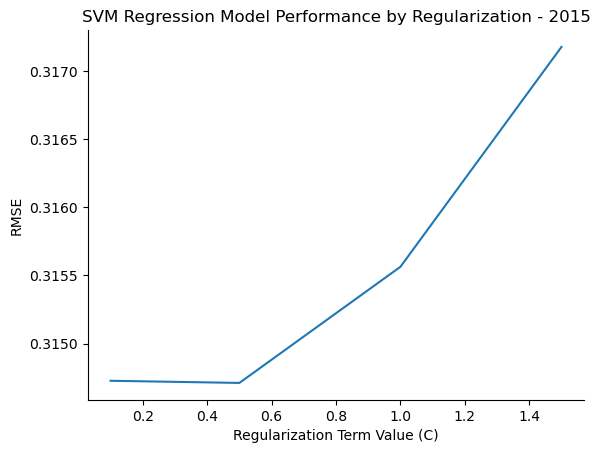

In [257]:
#graping station

Cs = results_df.param_C

rmses = results_df.RMSE

cmap = plt.get_cmap('coolwarm')

colors = cmap(np.linspace(0, 1, len(Cs)))

# Plot the sorted data
plt.plot(Cs, rmses)
plt.xlabel('Regularization Term Value (C)')
plt.ylabel('RMSE')
plt.title('SVM Regression Model Performance by Regularization - 2015')
plt.show()

<h3>Random Forest & Decision Trees</h3>

In [260]:
#imports for the RF
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RepeatedKFold
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
random_seed = 42

In [262]:
#set our x_train and y_train (fwd selected vars, departure delay time for y)

X_train, X_test, y_train, y_test = train_test_split(sampled_df[fwd_vars], sampled_df.DEPARTURE_DELAY,
                                                    test_size=0.25, random_state=random_seed)

In [264]:
# Define the model and cross-validation
model = RandomForestRegressor(random_state=random_seed)

repeated_cv = RepeatedKFold(n_splits     = 3, 
                            n_repeats    = 1,
                            random_state = random_seed
                           )     

# Define the parameter grid
param_dist = {
     'n_estimators': np.arange(100, 201, 25)
}

# Use GridSearchCV to find the best parameters

search = GridSearchCV(
    estimator=model,
    param_grid=param_dist,
    scoring='neg_root_mean_squared_error',  # RMSE but negated for maximization by GridSearchCV
    cv= repeated_cv,  # Number of folds for cross-validation -- Reduce this if efficiency is an issue
    n_jobs=-1,
    verbose = 1
)

# Fit the GridSearchCV
search.fit(X_train, y_train)  

# Extract results into a DataFrame
results = pd.DataFrame(search.cv_results_)

# Convert negative RMSE to positive
results['mean_test_RMSE'] = -results['mean_test_score']
results = results.sort_values(by = 'mean_test_RMSE')

# Sort by rank (best scores first)
top_10 = results[[
    'mean_test_RMSE',
    'param_n_estimators'
]].head(10)

# Print the results as a table
print("\nSearch Results (Top 10):\n")
print(top_10)  # Show the top 10 results

Fitting 3 folds for each of 5 candidates, totalling 15 fits


/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Search Results (Top 10):

   mean_test_RMSE  param_n_estimators
1        0.234801                 125
0        0.234814                 100
2        0.234893                 150
3        0.234989                 175
4        0.235003                 200


In [270]:
#running our best model on the data and generating feature importance

final_model = RandomForestRegressor(n_estimators = 125, random_state=random_seed)

final_model.fit(X_train, y_train)
importances = final_model.feature_importances_

In [272]:
forest_importances = pd.Series(importances, index=fwd_vars)
f_imp = forest_importances.sort_values(ascending = False)
f_imp

LATE_AIRCRAFT_DELAY    0.430319
AIRLINE_DELAY          0.419359
AIR_SYSTEM_DELAY       0.079838
WEATHER_DELAY          0.060363
TAXI_OUT               0.010120
dtype: float64

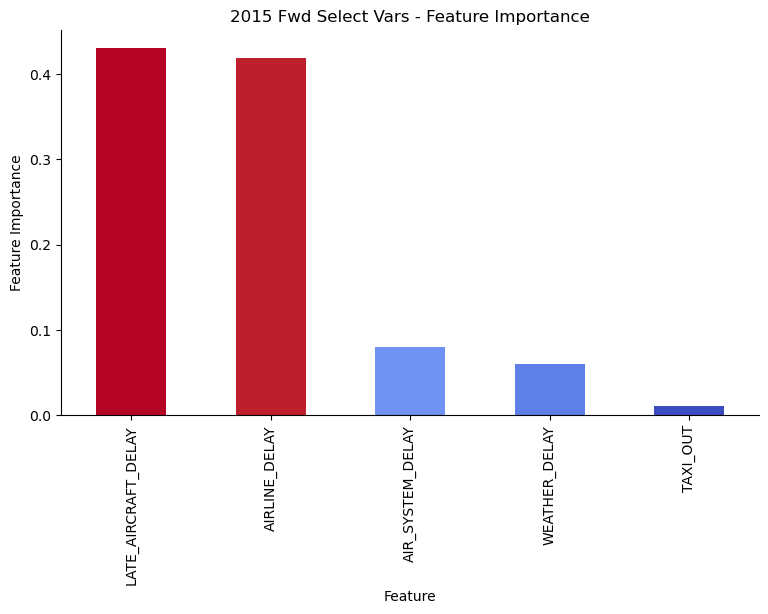

In [285]:
# Generate the bar plot
plt.figure(figsize=(9, 5))
# 1. Normalize values to [0, 1] for the colormap
norm = plt.Normalize(f_imp.min(), f_imp.max())

# 2. Choose a colormap (e.g., 'viridis', 'plasma', 'coolwarm')
cmap = plt.get_cmap('coolwarm')

# 3. Map values to colors
colors = cmap(norm(f_imp))

f_imp.plot.bar(color = colors, title='2015 Fwd Select Vars - Feature Importance')
plt.xlabel('Feature')
plt.ylabel('Feature Importance');

In [276]:
y_preds = final_model.predict(X_test)
test_RMSE = root_mean_squared_error(y_test, y_preds)
print('RMSE of our optimized model on the test set:', f"{test_RMSE:.3f}")

RMSE of our optimized model on the test set: 0.229


In [278]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

print('Cross Validation with the Decision Tree:')
print()

# Define the model
tree_model = DecisionTreeRegressor(random_state=random_seed)

# Define the parameter grid
param_dist = {
    'max_depth': randint(3, 20),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 20),
}

#RandomizedSearch to find the best parameters

random_search = RandomizedSearchCV(
    estimator=tree_model,
    param_distributions=param_dist,
    n_iter=5,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit the RandomizedSearchCV
random_search.fit(X_train, y_train)  

# Extract results into a DataFrame
results = pd.DataFrame(random_search.cv_results_)

# Convert negative RMSE to positive
results['mean_test_RMSE'] = -results['mean_test_score']
results = results.sort_values(by = 'mean_test_RMSE')

# Sort by rank (best scores first)
top_10 = results[[
    'mean_test_RMSE',
    'param_max_depth',
    'param_min_samples_split',
    'param_min_samples_leaf'
]].head(10)

# Print the results as a table
print("\nSearch Results (Top 10):\n")
print(top_10)  # Show the top 10 results

Cross Validation with the Decision Tree:

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Search Results (Top 10):

   mean_test_RMSE  param_max_depth  param_min_samples_split  \
2        0.242941               13                        9   
1        0.253023               10                       12   
4        0.264044                8                        2   
0        0.265382                9                       12   
3        0.373341                5                       13   

   param_min_samples_leaf  
2                       4  
1                       7  
4                       2  
0                      15  
3                       2  


In [280]:
#running our best model on the data and generating feature importance

final_tree = DecisionTreeRegressor(max_depth = 13, min_samples_split = 9,
                                   min_samples_leaf = 4, random_state=random_seed)

final_tree.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=13, min_samples_leaf=4, min_samples_split=9,
                      random_state=42)

In [282]:
tree_preds = final_tree.predict(X_test)
tree_RMSE = root_mean_squared_error(y_test, tree_preds)
print('RMSE of our optimized Decision Tree on the test set:', f"{tree_RMSE:.3f}")

RMSE of our optimized Decision Tree on the test set: 0.237


<h3>Conclusions</h3>

WEEK 8:

- Our baseline linear regression model was run with the 5 main delay types (AIR_SYSTEM_DELAY, SECURITY_DELAY, AIRLINE_DELAY, LATE_AIRCRAFT_DELAY, WEATHER_DELAY), and the RMSE of the model was about 0.262 with the R-squared being 0.931. The largest coefficients came for the features for AIRLINE_DELAY and LATE_AIRCRAFT DELAY
- Adding interaction terms and polynomial terms (squared distance) to the model did not result in any noticeable change in the R-squared
- We already know that one-hot encoding the airline/carrier variable doesn't lead to predictive variables either

WEEK 9:

- The Lasso regression kept TAXI_OUT, ARRIVAL_DELAY, AIRLINE_DELAY, and LATE_AIRCRAFT_DELAY for the regression. This model had an RMSE of 0.308, which is a little bit worse than the baseline model
- The Ridge regression did not leave out any variables but the RMSE of the model was approximately 0, and it definitely feels like we overfit because of us not leaving out any features. Largest coefficient by far was SCHEDULED_TIME (the estimated time of the flight, 2.04)
- Elastic net model got rid of coefficients for every variable except arrival delay (0.517), intercept is practically 0, and the RMSE is around 0.539, which is worst out of the regression variations
- Doesn't look like any of the 3 perform better than our baseline linear regression, but Lasso performs the best

WEEK 10:

- Compared to the baseline linear regression model we used with the 5 delay types, the same model with the 5 forward selected variables (TAXI_OUT, AIR_SYSTEM_DELAY, AIRLINE_DELAY, LATE_AIRCRAFT_DELAY, WEATHER_DELAY) performs slightly better with an RMSE of 0.249; the regression model that selected 5 variables via backwards selection performed about the same as the baseline model with an RMSE of 0.262. The backwards selection chose the SCHEDULED_TIME variable instead of TAXI_OUT, and it looks like that slightly made the model worse.
- The principal component regression with 5 components (RMSE = 0.381) is a little bit worse than the baseline and pretty much the worst out of all the models minus the elastic net model.
- The PLSR with 5 components to fit all inputs (RMSE = 0.234) performed the best out of the models we've seen so far with the 2015 data, but they're slightly harder to explain the coefficients

WEEK 11:

- In terms of regularization, I've been using the StandardScaler  for every model I've built. This puts all the numerical variables in the same scale by turning every value into a Z-score based on a given column's mean and standard deviation
- Logistic regression definitely wasn't as useful with this dataset, given that the target variables (ARRIVAL/DEPARTURE_DELAY) are both continuous and not binary variables. However, I created a binary variable from the data that indicates whether a flight was from a certain airline or not (in this case, Southwest). After running a logistic regression model with the 5 forward selected variables (TAXI_OUT, AIR_SYSTEM_DELAY, AIRLINE_DELAY, LATE_AIRCRAFT_DELAY, WEATHER_DELAY), our model came back with an accuracy of 0.782. This means that when asked to predict whether or not a flight belongs to Southwest Airlines, the model was able to classify correctly almost 78% of the time.